# 13b. 실험 6 (기록) — 고려대식 2클래스 모델: 혼효림을 침엽:활엽 몇 대 몇으로 나누나

**한 줄 요약:** 고려대 논문(Kim et al. 2025)처럼 **계절 사진(v2 25피처)만으로, 침엽·활엽 두 가지만 학습**한 모델을 05와 같은 LORO(8곳 × 시드 5)로 돌린다. 평가는 **혼효림까지 포함한 숲 전체**에서 한다.

**쉬운 설명**
- 고려대 모델은 혼효림을 배우지 않는다. 그래서 혼효림 픽셀도 결국 침엽 아니면 활엽으로 찍힌다
- 그 논문은 혼효림이 침엽 15 : 활엽 85로 나뉜다고 썼는데, **지도 면적에서 통계 면적을 빼서 계산한 값이고 픽셀로 확인한 적이 없다**
- 우리는 혼효림 픽셀마다 정답이 있으니, 모델이 실제로 몇 대 몇으로 나누는지 **직접 셀 수 있다** → 이게 이 노트북의 핵심
- 이 노트북은 **판정이 아니라 기록**이다 (판정은 13a에서 끝남)

**참고 숫자 [유도, 우리 확정계수 기준]:** 혼효림 탄소(92.01)가 맞으려면 침엽:활엽 = **41 : 59**로 나뉘어야 한다. 15:85로 나누면 혼효림 탄소를 **약 +6.2%** 많게 잡는다.

**끊겨도 이어서:** 폴드마다 저장 → 끊기면 **런타임 → 모두 실행**. 끝난 폴드는 건너뛴다.

**순서:** [1] 설정 → [2] 데이터 → [3] 사전 기록 → [4] LORO 40폴드 (약 1–1.5시간 [추정]) → [5] 모으기 → [6] 탄소 결과 (13a와 비교) → [7] 혼효 분배 → [8] 낙엽송·중요도

In [1]:
# [1] 설정 — 05·13a와 같은 값
!pip install -q rasterio

import os, json, time, gc, warnings
import numpy as np
import pandas as pd
import rasterio
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt
from google.colab import drive
warnings.filterwarnings('ignore', category=RuntimeWarning)

drive.mount('/content/drive')
D        = '/content/drive/MyDrive/forest/data'
OUT      = '/content/drive/MyDrive/forest/outputs'
FOLD_DIR = f'{OUT}/exp6b_folds'
os.makedirs(FOLD_DIR, exist_ok=True)

TRAIN_REGIONS = ['inje', 'hongcheon', 'gangneung', 'pyeongchang',
                 'bonghwa', 'geumsan', 'geochang', 'suncheon']
KR = {'inje': '인제', 'hongcheon': '홍천', 'gangneung': '강릉', 'pyeongchang': '평창',
      'bonghwa': '봉화', 'geumsan': '금산', 'geochang': '거창', 'suncheon': '순천'}
LARCH_CODE = 13

C    = {1: 79.25, 2: 101.02, 3: 92.01}       # 확정계수
C2V  = np.array([C[1], C[2]])                # 2클래스 예측에 쓰는 계수 (침엽·활엽)

SEEDS              = [16, 17, 18, 19, 20]
N_TRAIN_PER_REGION = 30_000
RF_PARAMS = dict(n_estimators=80, min_samples_leaf=20, max_features='sqrt',
                 class_weight='balanced', n_jobs=-1)

# 참고 숫자 [유도]
P_NEUTRAL = (C[2] - C[3]) / (C[2] - C[1])            # 혼효 탄소가 맞는 침엽 비율
C_1585    = 0.15 * C[1] + 0.85 * C[2]                # 15:85로 나눴을 때 혼효 ha당 탄소
print(f'혼효 탄소가 맞는 분배: 침엽 {P_NEUTRAL*100:.1f} : 활엽 {(1-P_NEUTRAL)*100:.1f}')
print(f'15:85로 나누면 혼효 ha당 {C_1585:.2f} tC (정답 {C[3]}) → {(C_1585/C[3]-1)*100:+.1f}%')

Mounted at /content/drive
혼효 탄소가 맞는 분배: 침엽 41.4 : 활엽 58.6
15:85로 나누면 혼효 ha당 97.75 tC (정답 92.01) → +6.2%


In [2]:
# [2] 데이터 — v2 캐시 + 수종(낙엽송)
X2, Y, OK, NTOT, LX = {}, {}, {}, {}, {}
for r in TRAIN_REGIONS:
    z = np.load(f'{OUT}/{r}_v2.npz')
    X2[r], Y[r], OK[r], NTOT[r] = z['X2'], z['y'], z['ok'], int(z['n_total'])
    NAMES2 = [str(s) for s in z['names']]
    with rasterio.open(f'{D}/{r}_species.tif') as s:
        sp = s.read(1)
    LX[r] = sp[z['rows'], z['cols']] == LARCH_CODE
    del sp, z; gc.collect()
assert len(NAMES2) == 25

rows = []
for r in TRAIN_REGIONS:
    y, ok = Y[r], OK[r]
    v = X2[r][ok]
    assert np.isfinite(v).all() and np.percentile(v[:, :20], 99) < 2.0, f'{r}: v2 값 이상'
    rows.append(dict(지역=KR[r], 평가픽셀=int(ok.sum()),
                     학습후보_침엽활엽=int((ok & (y <= 2)).sum()),
                     혼효비율=f'{(y[ok]==3).mean()*100:.1f}%'))
print(pd.DataFrame(rows).to_string(index=False))
print('\n학습후보 = 계절 값 있음 & 라벨이 침엽·활엽인 픽셀 (여기서 지역당 3만 개를 뽑는다)')

지역   평가픽셀  학습후보_침엽활엽  혼효비율
인제 600263     523177 12.8%
홍천 599525     519771 13.3%
강릉 600054     534987 10.8%
평창 600530     542401  9.7%
봉화 594698     553721  6.9%
금산 600247     503274 16.2%
거창 601114     480399 20.1%
순천 600844     539738 10.2%

학습후보 = 계절 값 있음 & 라벨이 침엽·활엽인 픽셀 (여기서 지역당 3만 개를 뽑는다)


In [3]:
# [3] 사전 기록 — 처음 실행할 때 exp6b_prereg.json 저장 (이후 덮어쓰지 않음)
CONFIRMED = True

PREREG = {
    'date': time.strftime('%Y-%m-%d %H:%M'),
    'type': '기록 (판정 아님). 판정은 13a에서 완료',
    'question': '고려대식 2클래스 모델(계절 입력, 혼효 제외 학습)을 처음 보는 지역에 쓰면 ① 혼효를 몇 대 몇으로 나누나 ② 탄소 오차는 얼마인가',
    'model': 'v2 25피처(4밴드×5계절 + 계절별 NDVI), RF 2클래스(침엽·활엽)',
    'train': '지역당 3만, 후보 = 계절 값 있음 & 라벨 1·2, default_rng(seed)로 무작위. RF 설정·LORO·시드는 05·13a와 같음',
    'eval': '평가 지역의 계절 값 있는 숲 픽셀 전체(혼효 포함). 13a와 같은 픽셀',
    'carbon': '예측 침엽×79.25 + 예측 활엽×101.02 vs 정답(혼효 92.01 포함). 딱 자르기 + 확률 섞기 둘 다',
    'mixed_split': '정답 혼효 픽셀 중 "침엽"으로 예측된 비율 (딱 자르기), 평균 P(침엽) (확률). 지역별·8곳 합산',
    'reference': {'koryo': '15:85 (뺄셈으로 산출, 픽셀 검증 없음)',
                  'carbon_neutral': f'{P_NEUTRAL*100:.1f}:{(1-P_NEUTRAL)*100:.1f} (우리 계수 기준 [유도])'},
    'prediction': ['[추정] 8곳 합산 혼효→침엽 비율은 15%보다 큼(20–40%)',
                   '[추정] 지역마다 크게 다름 (최대−최소 ≥ 15%p)',
                   '[추정] 2클래스 딱 자르기 지역 |오차| 평균 > 13a v1(1.39%)',
                   '[추정] 침엽·활엽 픽셀만 본 정확도(OA)는 고려대 83%보다 낮음(70–80%) — 그들은 무작위 분할, 우리는 지역 통째로 빼기'],
    'record_rule': '"15:85와 맞지 않음" = 8곳 합산 비율이 5/5 시드에서 10–20% 밖',
    'seeds': SEEDS, 'rf': {k: v for k, v in RF_PARAMS.items() if k != 'n_jobs'}, 'carbon_coeff': C,
}
pr_path = f'{OUT}/exp6b_prereg.json'
if os.path.exists(pr_path):
    print('저장된 사전 기록 (덮어쓰지 않음):\n')
    print(json.dumps(json.load(open(pr_path, encoding='utf-8')), ensure_ascii=False, indent=1))
elif CONFIRMED:
    json.dump(PREREG, open(pr_path, 'w', encoding='utf-8'), ensure_ascii=False, indent=1)
    print('사전 기록 저장:', pr_path)
else:
    print('CONFIRMED = True 로 바꿔 다시 실행')

사전 기록 저장: /content/drive/MyDrive/forest/outputs/exp6b_prereg.json


In [4]:
# [4] LORO 40폴드 — 폴드마다 저장. 끊기면 "모두 실행"
assert os.path.exists(f'{OUT}/exp6b_prereg.json'), '[3] 사전 기록 먼저'

def csum3(y):
    return float(sum((y == v).sum() * C[v] for v in (1, 2, 3)))

folds = [(s, r) for s in SEEDS for r in TRAIN_REGIONS]
todo  = [(s, r) for s, r in folds if not os.path.exists(f'{FOLD_DIR}/s{s}_{r}.npz')]
print(f'전체 {len(folds)}폴드 중 완료 {len(folds) - len(todo)}, 남은 {len(todo)}\n')

times = []
for k, (seed, test) in enumerate(todo, 1):
    t0  = time.time()
    rng = np.random.default_rng(seed)
    Xtr, ytr = [], []
    for r in TRAIN_REGIONS:
        if r == test: continue
        pool = np.where(OK[r] & (Y[r] <= 2))[0]
        i = rng.choice(pool, size=min(N_TRAIN_PER_REGION, len(pool)), replace=False)
        Xtr.append(X2[r][i]); ytr.append(Y[r][i])
    Xtr, ytr = np.concatenate(Xtr), np.concatenate(ytr)
    clf = RandomForestClassifier(random_state=seed, **RF_PARAMS)
    clf.fit(Xtr, ytr)
    assert list(clf.classes_) == [1, 2]
    del Xtr, ytr; gc.collect()

    it = np.where(OK[test])[0]
    yt, lx = Y[test][it], LX[test][it]
    P  = clf.predict_proba(X2[test][it])                   # 열 = 침엽·활엽
    imp = clf.feature_importances_
    del clf; gc.collect()
    h = (P.argmax(1) + 1).astype('int8')

    t_c  = csum3(yt)
    pc_h = float(C2V[h - 1].sum())
    pc_s = float((P @ C2V).sum())
    pure, mix = yt <= 2, yt == 3
    t_pure = csum3(yt[pure])
    out = dict(
        t_c=t_c, n_test=len(yt), n_total=NTOT[test], n_mix=int(mix.sum()),
        eh=(pc_h - t_c) * 100 / t_c, es=(pc_s - t_c) * 100 / t_c, pch=pc_h, pcs=pc_s,
        # 오차 나누기: 순수(침엽·활엽) 픽셀 몫 + 혼효 픽셀 몫 = eh
        eh_pure=(float(C2V[h[pure] - 1].sum()) - t_pure) * 100 / t_c,
        eh_mix=(float(C2V[h[mix] - 1].sum()) - mix.sum() * C[3]) * 100 / t_c,
        e_1585=mix.sum() * (C_1585 - C[3]) * 100 / t_c,       # 혼효를 정확히 15:85로 나눴다면 그 몫
        oa_pure=float((h[pure] == yt[pure]).mean()),
        f1_pure=f1_score(yt[pure], h[pure], average='macro', labels=[1, 2]),
        mix_conif_h=float((h[mix] == 1).mean()) if mix.any() else np.nan,
        mix_conif_s=float(P[mix, 0].mean()) if mix.any() else np.nan,
        cm=np.array([[int(((yt == a) & (h == b)).sum()) for b in (1, 2)] for a in (1, 2, 3)]),
        larch_hit=float((h[(yt == 1) & lx] == 1).mean()) if ((yt == 1) & lx).any() else np.nan,
        other_hit=float((h[(yt == 1) & ~lx] == 1).mean()),
        imp=imp, pred=h)
    np.savez_compressed(f'{FOLD_DIR}/s{seed}_{test}.npz', **out)
    del P, h, out; gc.collect()

    z = np.load(f'{FOLD_DIR}/s{seed}_{test}.npz')
    dt = time.time() - t0; times.append(dt)
    eta = np.mean(times) * (len(todo) - k) / 60
    print(f'[{k:2d}/{len(todo)}] s{seed} {KR[test]:3s}  탄소오차 {float(z["eh"]):+6.2f}% (확률 {float(z["es"]):+6.2f})  '
          f'혼효→침엽 {float(z["mix_conif_h"])*100:4.1f}%  OA(순수) {float(z["oa_pure"])*100:4.1f}%  '
          f'{dt:4.0f}초  남은 약 {eta:.0f}분')
print('\n모든 폴드 완료')

전체 40폴드 중 완료 0, 남은 40

[ 1/40] s16 인제   탄소오차  +1.31% (확률  +0.73)  혼효→침엽 38.2%  OA(순수) 83.0%   114초  남은 약 74분
[ 2/40] s16 홍천   탄소오차  +0.67% (확률  -0.12)  혼효→침엽 42.8%  OA(순수) 81.6%    98초  남은 약 67분
[ 3/40] s16 강릉   탄소오차  -0.31% (확률  -1.00)  혼효→침엽 61.1%  OA(순수) 83.2%    94초  남은 약 63분
[ 4/40] s16 평창   탄소오차  +1.73% (확률  +0.95)  혼효→침엽 46.3%  OA(순수) 80.9%    96초  남은 약 60분
[ 5/40] s16 봉화   탄소오차  +0.14% (확률  +0.27)  혼효→침엽 61.3%  OA(순수) 85.1%    97초  남은 약 58분
[ 6/40] s16 금산   탄소오차  +1.67% (확률  +0.31)  혼효→침엽 34.5%  OA(순수) 75.9%    96초  남은 약 56분
[ 7/40] s16 거창   탄소오차  -0.86% (확률  -0.81)  혼효→침엽 57.1%  OA(순수) 85.7%    94초  남은 약 54분
[ 8/40] s16 순천   탄소오차  -2.51% (확률  -2.29)  혼효→침엽 72.1%  OA(순수) 83.5%    96초  남은 약 52분
[ 9/40] s17 인제   탄소오차  +1.31% (확률  +0.75)  혼효→침엽 38.3%  OA(순수) 83.1%    98초  남은 약 51분
[10/40] s17 홍천   탄소오차  +0.68% (확률  -0.09)  혼효→침엽 43.4%  OA(순수) 81.6%   100초  남은 약 49분
[11/40] s17 강릉   탄소오차  -0.36% (확률  -1.03)  혼효→침엽 61.8%  OA(순수) 83.2%    95초  남은 약 47분
[12/40] s17 평창   탄소오차  +1.78% (

In [5]:
# [5] 폴드 결과 모으기 → exp6b_results.npz (시드 × 지역)
ns, nr = len(SEEDS), len(TRAIN_REGIONS)
KEYS = ['t_c', 'n_test', 'n_mix', 'eh', 'es', 'pch', 'pcs', 'eh_pure', 'eh_mix', 'e_1585',
        'oa_pure', 'f1_pure', 'mix_conif_h', 'mix_conif_s', 'larch_hit', 'other_hit']
R = {k: np.full((ns, nr), np.nan) for k in KEYS}
CM = np.zeros((ns, nr, 3, 2)); IMP = np.full((ns, nr, 25), np.nan)
for i, s in enumerate(SEEDS):
    for j, r in enumerate(TRAIN_REGIONS):
        f = f'{FOLD_DIR}/s{s}_{r}.npz'
        if not os.path.exists(f): continue
        z = np.load(f)
        for k in KEYS: R[k][i, j] = float(z[k])
        CM[i, j] = z['cm']; IMP[i, j] = z['imp']
miss = int(np.isnan(R['t_c']).sum())
assert miss == 0, f'미완료 폴드 {miss}개 — [4]를 다시 실행'
NT_ = np.array([NTOT[r] for r in TRAIN_REGIONS], float)
np.savez(f'{OUT}/exp6b_results.npz', **R, cm=CM, imp=IMP, n_total=NT_,
         seeds=np.array(SEEDS), regions=np.array(TRAIN_REGIONS), names=np.array(NAMES2))
print('저장:', f'{OUT}/exp6b_results.npz')

저장: /content/drive/MyDrive/forest/outputs/exp6b_results.npz


In [6]:
# [6] 탄소 결과 — 13a(v1, v1+계절)와 같은 픽셀·같은 시드로 비교
A = None
if os.path.exists(f'{OUT}/exp6a_results.npz'):
    A = np.load(f'{OUT}/exp6a_results.npz')
    assert (A['n_test'] == R['n_test']).all(), '13a와 평가 픽셀 수가 다름 — 멈추고 보고'

tab = pd.DataFrame({'지역': [KR[r] for r in TRAIN_REGIONS]})
if A is not None:
    tab['v1 딱'] = A['v1_eh'].mean(0); tab['계절 딱'] = A['sea_eh'].mean(0)
tab['2클래스 딱'] = R['eh'].mean(0)
tab['  ├ 순수 몫'] = R['eh_pure'].mean(0)
tab['  └ 혼효 몫'] = R['eh_mix'].mean(0)
tab['(15:85였다면 혼효 몫)'] = R['e_1585'].mean(0)
if A is not None:
    tab['v1 확률'] = A['v1_es'].mean(0); tab['계절 확률'] = A['sea_es'].mean(0)
tab['2클래스 확률'] = R['es'].mean(0)
tab.to_csv(f'{OUT}/exp6b_by_region.csv', index=False)
print(tab.round(2).to_string(index=False))
print('(탄소 오차 %, 5시드 평균, 부호 포함. 순수 몫 + 혼효 몫 = 2클래스 딱)\n')

dens = lambda pc: pc / R['n_test']
tot_t = (dens(R['t_c']) * NT_).sum(1)
def agg(pc): return ((dens(pc) * NT_).sum(1) - tot_t) * 100 / tot_t
print(f'지역 |오차| 평균   2클래스 딱 {np.abs(R["eh"]).mean():.2f}%  확률 {np.abs(R["es"]).mean():.2f}%', end='')
if A is not None:
    print(f'   (13a: v1 딱 {np.abs(A["v1_eh"]).mean():.2f} / 계절 딱 {np.abs(A["sea_eh"]).mean():.2f} / '
          f'v1 확률 {np.abs(A["v1_es"]).mean():.2f} / 계절 확률 {np.abs(A["sea_es"]).mean():.2f})')
else:
    print()
print(f'면적가중 합산     2클래스 딱 {agg(R["pch"]).mean():+.2f}%  확률 {agg(R["pcs"]).mean():+.2f}%', end='')
if A is not None:
    print(f'   (13a: v1 딱 {agg(A["v1_pch"]).mean():+.2f} / 계절 딱 {agg(A["sea_pch"]).mean():+.2f})')
else:
    print()
print(f'\n침엽·활엽 픽셀만 본 정확도 OA {R["oa_pure"].mean()*100:.1f}% (지역 {np.nanmin(R["oa_pure"].mean(0))*100:.1f}–'
      f'{np.nanmax(R["oa_pure"].mean(0))*100:.1f}%), F1 {R["f1_pure"].mean():.3f}   ← 고려대 OA 83.1% (무작위 분할, U-Net)')
print(f'예측: 2클래스 딱 지역 |오차| 평균 > 1.39% → {"맞음" if np.abs(R["eh"]).mean() > 1.39 else "틀림"}')

지역  v1 딱  계절 딱  2클래스 딱    ├ 순수 몫    └ 혼효 몫  (15:85였다면 혼효 몫)  v1 확률  계절 확률  2클래스 확률
인제  2.40  2.16    1.32      1.22      0.10             0.82   1.69   1.48     0.73
홍천  0.73  0.88    0.64      0.71     -0.06             0.83  -0.08   0.01    -0.12
강릉 -0.47 -0.22   -0.34      0.18     -0.52             0.68  -1.13  -0.95    -1.02
평창  2.38  2.22    1.75      1.86     -0.11             0.61   1.59   1.47     0.97
봉화  1.23  1.04    0.15      0.49     -0.35             0.45   1.50   1.32     0.22
금산  2.17  2.17    1.70      1.43      0.27             1.00   0.38   0.39     0.37
거창  0.38 -0.06   -0.80     -0.03     -0.76             1.31   0.42   0.13    -0.81
순천 -1.36 -1.07   -2.44     -1.68     -0.76             0.66  -1.08  -0.83    -2.27
(탄소 오차 %, 5시드 평균, 부호 포함. 순수 몫 + 혼효 몫 = 2클래스 딱)

지역 |오차| 평균   2클래스 딱 1.14%  확률 0.81%   (13a: v1 딱 1.39 / 계절 딱 1.23 / v1 확률 0.98 / 계절 확률 0.82)
면적가중 합산     2클래스 딱 +0.41%  확률 -0.08%   (13a: v1 딱 +1.04 / 계절 딱 +1.00)

침엽·활엽 픽셀만 본 정확도 OA 82.4% (지역 75.9–85.8%),

In [7]:
# [7] 혼효 분배 — 이 노트북의 핵심. 정답 혼효 픽셀 중 "침엽"으로 간 비율
mt = pd.DataFrame({
    '지역': [KR[r] for r in TRAIN_REGIONS],
    '혼효 픽셀': R['n_mix'][0].astype(int),
    '침엽으로(딱)%': R['mix_conif_h'].mean(0) * 100,
    '시드 범위': [f'{R["mix_conif_h"][:, j].min()*100:.1f}–{R["mix_conif_h"][:, j].max()*100:.1f}' for j in range(nr)],
    '평균 P(침엽)%': R['mix_conif_s'].mean(0) * 100,
})
mt.to_csv(f'{OUT}/exp6b_mixed_split.csv', index=False)
print(mt.round(1).to_string(index=False))

pooled_h = np.nansum(R['mix_conif_h'] * R['n_mix'], 1) / R['n_mix'].sum(1) * 100     # 시드별 8곳 합산
pooled_s = np.nansum(R['mix_conif_s'] * R['n_mix'], 1) / R['n_mix'].sum(1) * 100
reg = R['mix_conif_h'].mean(0) * 100
print(f'\n8곳 합산 혼효→침엽 (시드별, 딱)   ' + ' '.join(f'{x:.1f}' for x in pooled_h))
print(f'8곳 합산 평균 P(침엽) (시드별)    ' + ' '.join(f'{x:.1f}' for x in pooled_s))
print(f'참고: 고려대 15 / 탄소가 맞는 비율 {P_NEUTRAL*100:.1f}')
outside = int(((pooled_h < 10) | (pooled_h > 20)).sum())
print(f'\n기록 규칙: 10–20% 밖인 시드 {outside}/5 → {"15:85와 맞지 않음" if outside == 5 else "15:85와 맞지 않는다고 할 수 없음"}')
print(f'예측 ① 합산 20–40%: {pooled_h.mean():.1f}% → {"맞음" if 20 <= pooled_h.mean() <= 40 else "틀림"}')
print(f'예측 ② 지역 최대−최소 ≥ 15%p: {reg.max() - reg.min():.1f}%p → {"맞음" if reg.max() - reg.min() >= 15 else "틀림"}')

지역  혼효 픽셀  침엽으로(딱)%     시드 범위  평균 P(침엽)%
인제  77086      38.2 37.8–38.3       42.5
홍천  79754      43.4 42.8–43.7       46.2
강릉  65067      61.4 61.1–61.8       58.7
평창  58129      46.1 45.8–46.3       48.6
봉화  40977      61.5 61.2–62.1       58.9
금산  96973      34.3 34.0–34.5       40.0
거창 120715      56.8 56.0–57.8       56.0
순천  61106      71.9 71.4–72.7       65.9

8곳 합산 혼효→침엽 (시드별, 딱)   50.3 50.4 50.2 50.5 50.1
8곳 합산 평균 P(침엽) (시드별)    51.2 51.1 51.1 51.2 51.2
참고: 고려대 15 / 탄소가 맞는 비율 41.4

기록 규칙: 10–20% 밖인 시드 5/5 → 15:85와 맞지 않음
예측 ① 합산 20–40%: 50.3% → 틀림
예측 ② 지역 최대−최소 ≥ 15%p: 37.6%p → 맞음


지역  낙엽송→침엽%  다른침엽→침엽%
인제     60.5      82.3
홍천     66.1      80.1
강릉     50.5      84.4
평창     63.3      78.6
봉화     65.5      91.2
금산     54.1      60.9
거창     65.1      92.0
순천     57.3      92.4
(침엽 라벨 픽셀 중 "침엽"으로 맞힌 비율. 2클래스라 13a 3클래스 숫자보다 높게 나오는 게 정상 — 직접 비교는 하지 않음)

중요도 상위 10: s2_B8 0.161, s1_ndvi 0.145, s2_ndvi 0.130, s5_ndvi 0.101, s3_ndvi 0.090, s3_B8 0.067, s1_B4 0.044, s1_B2 0.030, s5_B4 0.021, s1_B3 0.021
  3–4월    0.254
  5–6월    0.328
  7–8월    0.203
  9–10월   0.047
  11–12월  0.167


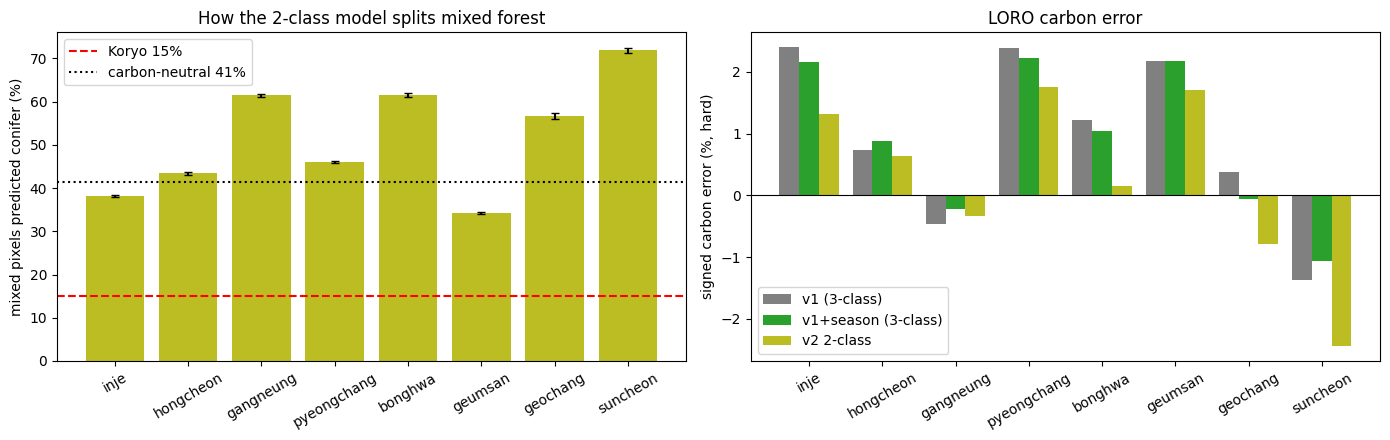

→ [6]·[7]·[8] 출력을 채팅에 붙여넣기


In [8]:
# [8] 낙엽송 · 피처 중요도 · 그림
lt = pd.DataFrame({'지역': [KR[r] for r in TRAIN_REGIONS],
                   '낙엽송→침엽%': R['larch_hit'].mean(0) * 100,
                   '다른침엽→침엽%': R['other_hit'].mean(0) * 100})
print(lt.round(1).to_string(index=False))
print('(침엽 라벨 픽셀 중 "침엽"으로 맞힌 비율. 2클래스라 13a 3클래스 숫자보다 높게 나오는 게 정상 — 직접 비교는 하지 않음)\n')

imp = IMP.reshape(-1, 25).mean(0)
o = np.argsort(imp)[::-1]
print('중요도 상위 10: ' + ', '.join(f'{NAMES2[k]} {imp[k]:.3f}' for k in o[:10]))
for t, lab in zip(['s1', 's2', 's3', 's4', 's5'], ['3–4월', '5–6월', '7–8월', '9–10월', '11–12월']):
    print(f'  {lab:7s} {sum(imp[k] for k, n in enumerate(NAMES2) if n.startswith(t + "_")):.3f}')
pd.DataFrame({'feature': NAMES2, 'importance': imp}).to_csv(f'{OUT}/exp6b_importance.csv', index=False)

x = np.arange(nr)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(x, R['mix_conif_h'].mean(0) * 100, yerr=R['mix_conif_h'].std(0, ddof=1) * 100, capsize=3, color='tab:olive')
ax[0].axhline(15, c='r', ls='--', label='Koryo 15%')
ax[0].axhline(P_NEUTRAL * 100, c='k', ls=':', label=f'carbon-neutral {P_NEUTRAL*100:.0f}%')
ax[0].set_xticks(x); ax[0].set_xticklabels(TRAIN_REGIONS, rotation=30)
ax[0].set_ylabel('mixed pixels predicted conifer (%)'); ax[0].set_title('How the 2-class model splits mixed forest'); ax[0].legend()
w = .27
if A is not None:
    ax[1].bar(x - w, A['v1_eh'].mean(0), width=w, color='gray', label='v1 (3-class)')
    ax[1].bar(x, A['sea_eh'].mean(0), width=w, color='tab:green', label='v1+season (3-class)')
ax[1].bar(x + w, R['eh'].mean(0), width=w, color='tab:olive', label='v2 2-class')
ax[1].axhline(0, c='k', lw=.8)
ax[1].set_xticks(x); ax[1].set_xticklabels(TRAIN_REGIONS, rotation=30)
ax[1].set_ylabel('signed carbon error (%, hard)'); ax[1].set_title('LORO carbon error'); ax[1].legend()
plt.tight_layout(); plt.savefig(f'{OUT}/exp6b.png', dpi=150); plt.show()
print('→ [6]·[7]·[8] 출력을 채팅에 붙여넣기')